In [1]:
import kagglehub

path = kagglehub.dataset_download(
    "ucimachinelearning/lung-nodule-dataset"
)

print("Dataset path:", path)

100%|██████████| 1.34G/1.34G [01:07<00:00, 21.4MB/s]

Extracting files...


Dataset path: /root/.cache/kagglehub/datasets/ucimachinelearning/lung-nodule-dataset/versions/1


In [2]:
import os

DATASET_PATH = "/root/.cache/kagglehub/datasets/ucimachinelearning/lung-nodule-dataset/versions/1"

print("Dataset structure:\n")

for root, dirs, files in os.walk(DATASET_PATH):
    level = root.replace(DATASET_PATH, "").count(os.sep)

    # Don't go too deep
    if level > 4:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}📁 {os.path.basename(root)}/")

    # Show first 10 files from each folder
    for file in files[:10]:
        print(f"{indent}    📄 {file}")

Dataset structure:

📁 1/
    📁 Lung_Nodule_Dataset/
        📁 Lung_Nodule_Dataset/
            📁 Images/
                📄 3158.png
                📄 3260.png
                📄 4907.png
                📄 874.png
                📄 4967.png
                📄 1337.png
                📄 1631.png
                📄 3213.png
                📄 3184.png
                📄 1042.png
            📁 Annotations/
                📄 3158.png
                📄 3260.png
                📄 4907.png
                📄 874.png
                📄 4967.png
                📄 1337.png
                📄 1631.png
                📄 3213.png
                📄 3184.png
                📄 1042.png
    📁 Lung_CT_Class_Dataset/
        📁 Lung_CT_Class_Dataset/
            📁 Healthy/
                📄 healthy_07615.png
                📄 healthy_02309.png
                📄 healthy_08371.png
                📄 healthy_08506.png
                📄 healthy_07562.png
                📄 healthy_09988.png
                📄 healthy_088

In [3]:
from collections import Counter

extensions = Counter()

for root, dirs, files in os.walk(DATASET_PATH):
    for file in files:
        ext = os.path.splitext(file)[1].lower()
        extensions[ext] += 1

print("File types:")
for ext, count in extensions.most_common():
    print(f"{ext or 'NO EXTENSION':15} {count}")

File types:
.png            30572


In [4]:
print("Top-level contents:")
print(os.listdir(DATASET_PATH))

Top-level contents:
['Lung_Nodule_Dataset', 'Lung_CT_Class_Dataset']


In [5]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:
from tensorflow.keras import mixed_precision

mixed_precision.set_global_policy("mixed_float16")

print("Mixed precision policy:", mixed_precision.global_policy())

Mixed precision policy: <DTypePolicy "mixed_float16">


In [7]:
DATASET_PATH = (
    "/root/.cache/kagglehub/datasets/"
    "ucimachinelearning/lung-nodule-dataset/versions/1"
)

SEGMENTATION_PATH = os.path.join(
    DATASET_PATH,
    "Lung_Nodule_Dataset",
    "Lung_Nodule_Dataset"
)

IMAGE_DIR = os.path.join(
    SEGMENTATION_PATH,
    "Images"
)

MASK_DIR = os.path.join(
    SEGMENTATION_PATH,
    "Annotations"
)

print("Image directory:")
print(IMAGE_DIR)

print("\nMask directory:")
print(MASK_DIR)

print("\nImage directory exists:", os.path.exists(IMAGE_DIR))
print("Mask directory exists :", os.path.exists(MASK_DIR))

Image directory:
/root/.cache/kagglehub/datasets/ucimachinelearning/lung-nodule-dataset/versions/1/Lung_Nodule_Dataset/Lung_Nodule_Dataset/Images

Mask directory:
/root/.cache/kagglehub/datasets/ucimachinelearning/lung-nodule-dataset/versions/1/Lung_Nodule_Dataset/Lung_Nodule_Dataset/Annotations

Image directory exists: True
Mask directory exists : True


In [8]:
image_files = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(".png")
])

mask_files = sorted([
    f for f in os.listdir(MASK_DIR)
    if f.lower().endswith(".png")
])

print("CT Images :", len(image_files))
print("Masks     :", len(mask_files))

CT Images : 5070
Masks     : 5070


In [9]:
image_set = set(image_files)
mask_set = set(mask_files)

matched_files = sorted(image_set.intersection(mask_set))

missing_masks = sorted(image_set - mask_set)
missing_images = sorted(mask_set - image_set)

print("Matched pairs :", len(matched_files))
print("Missing masks :", len(missing_masks))
print("Missing images:", len(missing_images))

Matched pairs : 5070
Missing masks : 0
Missing images: 0


In [10]:
for filename in matched_files[:10]:

    image_path = os.path.join(IMAGE_DIR, filename)
    mask_path = os.path.join(MASK_DIR, filename)

    image = Image.open(image_path)
    mask = Image.open(mask_path)

    print(
        filename,
        "| Image:",
        image.size,
        image.mode,
        "| Mask:",
        mask.size,
        mask.mode
    )

1.png | Image: (256, 256) RGB | Mask: (256, 256) RGB
10.png | Image: (256, 256) RGB | Mask: (256, 256) RGB
100.png | Image: (256, 256) RGB | Mask: (256, 256) RGB
1000.png | Image: (256, 256) RGB | Mask: (256, 256) RGB
1001.png | Image: (256, 256) RGB | Mask: (256, 256) RGB
1002.png | Image: (256, 256) RGB | Mask: (256, 256) RGB
1003.png | Image: (256, 256) RGB | Mask: (256, 256) RGB
1004.png | Image: (256, 256) RGB | Mask: (256, 256) RGB
1005.png | Image: (256, 256) RGB | Mask: (256, 256) RGB
1006.png | Image: (256, 256) RGB | Mask: (256, 256) RGB


In [11]:
sample_file = matched_files[0]

image = np.array(
    Image.open(
        os.path.join(IMAGE_DIR, sample_file)
    )
)

mask = np.array(
    Image.open(
        os.path.join(MASK_DIR, sample_file)
    )
)

print("IMAGE")
print("Shape :", image.shape)
print("Type  :", image.dtype)
print("Min   :", image.min())
print("Max   :", image.max())

print("\nMASK")
print("Shape :", mask.shape)
print("Type  :", mask.dtype)
print("Min   :", mask.min())
print("Max   :", mask.max())

print("\nUnique mask values:")
print(np.unique(mask)[:50])

IMAGE
Shape : (256, 256, 3)
Type  : uint8
Min   : 0
Max   : 255

MASK
Shape : (256, 256, 3)
Type  : uint8
Min   : 0
Max   : 255

Unique mask values:
[  0  12  17  21 255]


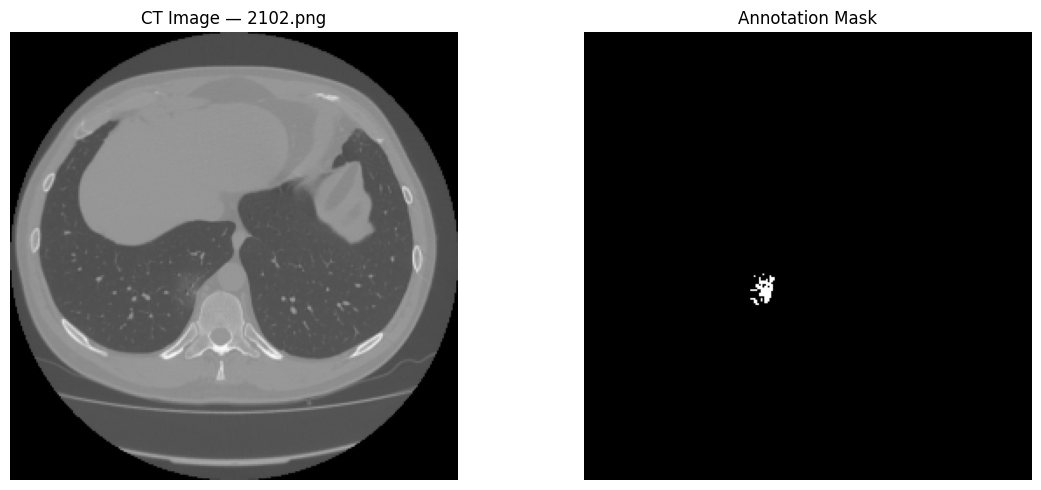

In [12]:
sample_file = random.choice(matched_files)

image = Image.open(
    os.path.join(IMAGE_DIR, sample_file)
)

mask = Image.open(
    os.path.join(MASK_DIR, sample_file)
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title(f"CT Image — {sample_file}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Annotation Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

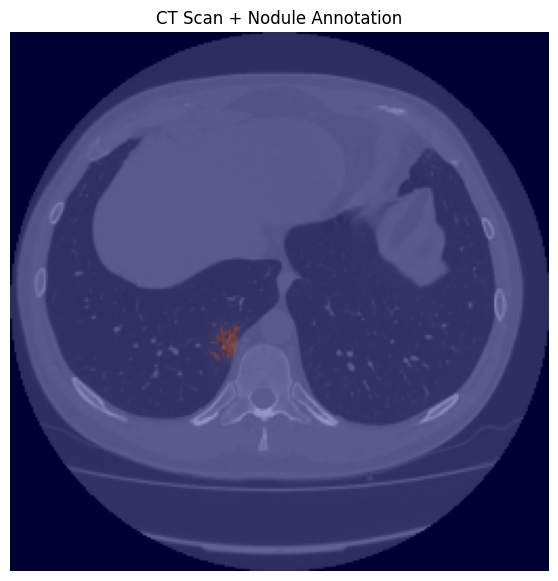

In [13]:
image_np = np.array(image)

mask_np = np.array(mask)

# Handle RGB masks if necessary
if mask_np.ndim == 3:
    mask_np = mask_np[..., 0]

# Convert to binary
binary_mask = (mask_np > 0).astype(np.float32)

plt.figure(figsize=(7, 7))

plt.imshow(image_np, cmap="gray")

plt.imshow(
    binary_mask,
    cmap="jet",
    alpha=0.4
)

plt.title("CT Scan + Nodule Annotation")
plt.axis("off")

plt.show()

In [14]:
positive_masks = 0
empty_masks = 0

for filename in matched_files:

    mask_path = os.path.join(
        MASK_DIR,
        filename
    )

    mask = np.array(
        Image.open(mask_path)
    )

    if np.any(mask > 0):
        positive_masks += 1
    else:
        empty_masks += 1

print("Total masks   :", len(matched_files))
print("Positive masks:", positive_masks)
print("Empty masks   :", empty_masks)

Total masks   : 5070
Positive masks: 5068
Empty masks   : 2


In [15]:
mask_coverage = []

for filename in matched_files:

    mask = np.array(
        Image.open(
            os.path.join(MASK_DIR, filename)
        )
    )

    if mask.ndim == 3:
        mask = mask[..., 0]

    binary = mask > 0

    coverage = (
        np.sum(binary) /
        binary.size
    )

    mask_coverage.append(coverage)

mask_coverage = np.array(mask_coverage)

print(
    "Average nodule coverage:",
    f"{mask_coverage.mean() * 100:.4f}%"
)

print(
    "Median nodule coverage:",
    f"{np.median(mask_coverage) * 100:.4f}%"
)

print(
    "Maximum nodule coverage:",
    f"{mask_coverage.max() * 100:.4f}%"
)

Average nodule coverage: 1.5377%
Median nodule coverage: 0.7462%
Maximum nodule coverage: 28.0731%


In [16]:
import pandas as pd

data = []

for filename in matched_files:

    data.append({
        "filename": filename,
        "image_path": os.path.join(
            IMAGE_DIR,
            filename
        ),
        "mask_path": os.path.join(
            MASK_DIR,
            filename
        )
    })

df = pd.DataFrame(data)

print("Total usable samples:", len(df))

df.head()

Total usable samples: 5070


,filename,image_path,mask_path
0,1.png,/root/.cache/kagglehub/datasets/ucimachinelear...,/root/.cache/kagglehub/datasets/ucimachinelear...
1,10.png,/root/.cache/kagglehub/datasets/ucimachinelear...,/root/.cache/kagglehub/datasets/ucimachinelear...
2,100.png,/root/.cache/kagglehub/datasets/ucimachinelear...,/root/.cache/kagglehub/datasets/ucimachinelear...
3,1000.png,/root/.cache/kagglehub/datasets/ucimachinelear...,/root/.cache/kagglehub/datasets/ucimachinelear...
4,1001.png,/root/.cache/kagglehub/datasets/ucimachinelear...,/root/.cache/kagglehub/datasets/ucimachinelear...


In [17]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    shuffle=True
)

train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training   :", len(train_df))
print("Validation :", len(valid_df))
print("Testing    :", len(test_df))

print(
    "\nTotal:",
    len(train_df) +
    len(valid_df) +
    len(test_df)
)

Training   : 4056
Validation : 507
Testing    : 507

Total: 5070


In [18]:
total = len(df)

print(
    f"Training   : {len(train_df) / total * 100:.2f}%"
)

print(
    f"Validation : {len(valid_df) / total * 100:.2f}%"
)

print(
    f"Testing    : {len(test_df) / total * 100:.2f}%"
)

Training   : 80.00%
Validation : 10.00%
Testing    : 10.00%


In [19]:
train_df.to_csv(
    "/content/train_segmentation.csv",
    index=False
)

valid_df.to_csv(
    "/content/valid_segmentation.csv",
    index=False
)

test_df.to_csv(
    "/content/test_segmentation.csv",
    index=False
)

print("Dataset splits saved.")

Dataset splits saved.


In [20]:
print("=" * 60)
print("MODEL 2 — PHASE 1 COMPLETE")
print("=" * 60)

print(f"Matched CT/Mask pairs : {len(df)}")
print(f"Training samples      : {len(train_df)}")
print(f"Validation samples    : {len(valid_df)}")
print(f"Testing samples       : {len(test_df)}")

print("\nDataset:")
print("Kaggle Lung Nodule Dataset")

print("\nTask:")
print("Lung Nodule Segmentation")

print("\nPlanned Model:")
print("U-Net")

print("\nHardware:")
print("T4 GPU")

print("=" * 60)

MODEL 2 — PHASE 1 COMPLETE
Matched CT/Mask pairs : 5070
Training samples      : 4056
Validation samples    : 507
Testing samples       : 507

Dataset:
Kaggle Lung Nodule Dataset

Task:
Lung Nodule Segmentation

Planned Model:
U-Net

Hardware:
T4 GPU


In [21]:
# ============================================================
# PHASE 2 - CONFIGURATION
# ============================================================

IMG_HEIGHT = 256
IMG_WIDTH = 256
IMG_CHANNELS = 1

BATCH_SIZE = 16
SEED = 42

AUTOTUNE = tf.data.AUTOTUNE

print("Image Size :", (IMG_HEIGHT, IMG_WIDTH))
print("Channels   :", IMG_CHANNELS)
print("Batch Size :", BATCH_SIZE)

Image Size : (256, 256)
Channels   : 1
Batch Size : 16


In [22]:
print("Training samples   :", len(train_df))
print("Validation samples :", len(valid_df))
print("Testing samples    :", len(test_df))

print("\nColumns:")
print(train_df.columns.tolist())

train_df.head()

Training samples   : 4056
Validation samples : 507
Testing samples    : 507

Columns:
['filename', 'image_path', 'mask_path']


,filename,image_path,mask_path
0,2905.png,/root/.cache/kagglehub/datasets/ucimachinelear...,/root/.cache/kagglehub/datasets/ucimachinelear...
1,1682.png,/root/.cache/kagglehub/datasets/ucimachinelear...,/root/.cache/kagglehub/datasets/ucimachinelear...
2,1980.png,/root/.cache/kagglehub/datasets/ucimachinelear...,/root/.cache/kagglehub/datasets/ucimachinelear...
3,2281.png,/root/.cache/kagglehub/datasets/ucimachinelear...,/root/.cache/kagglehub/datasets/ucimachinelear...
4,3473.png,/root/.cache/kagglehub/datasets/ucimachinelear...,/root/.cache/kagglehub/datasets/ucimachinelear...


In [23]:
train_images = train_df["image_path"].values
train_masks = train_df["mask_path"].values

valid_images = valid_df["image_path"].values
valid_masks = valid_df["mask_path"].values

test_images = test_df["image_path"].values
test_masks = test_df["mask_path"].values

print("Train:", len(train_images))
print("Valid:", len(valid_images))
print("Test :", len(test_images))

Train: 4056
Valid: 507
Test : 507


In [24]:
def load_ct_image(image_path):

    image = tf.io.read_file(image_path)

    image = tf.image.decode_png(
        image,
        channels=1
    )

    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH],
        method="bilinear"
    )

    image = tf.cast(
        image,
        tf.float32
    )

    image = image / 255.0

    return image

In [25]:
def load_mask(mask_path):

    mask = tf.io.read_file(mask_path)

    mask = tf.image.decode_png(
        mask,
        channels=1
    )

    mask = tf.image.resize(
        mask,
        [IMG_HEIGHT, IMG_WIDTH],
        method="nearest"
    )

    mask = tf.cast(
        mask,
        tf.float32
    )

    # Convert ANY positive annotation pixel to 1.
    mask = tf.cast(
        mask > 0,
        tf.float32
    )

    return mask

In [26]:
def load_image_mask(image_path, mask_path):

    image = load_ct_image(image_path)

    mask = load_mask(mask_path)

    return image, mask

In [27]:
sample_image_path = train_df.iloc[0]["image_path"]
sample_mask_path = train_df.iloc[0]["mask_path"]

sample_image, sample_mask = load_image_mask(
    sample_image_path,
    sample_mask_path
)

print("Image shape :", sample_image.shape)
print("Mask shape  :", sample_mask.shape)

print("\nImage:")
print("Min:", tf.reduce_min(sample_image).numpy())
print("Max:", tf.reduce_max(sample_image).numpy())

print("\nMask:")
print("Min:", tf.reduce_min(sample_mask).numpy())
print("Max:", tf.reduce_max(sample_mask).numpy())

print(
    "Unique mask values:",
    np.unique(sample_mask.numpy())
)

Image shape : (256, 256, 1)
Mask shape  : (256, 256, 1)

Image:
Min: 0.0
Max: 0.95686275

Mask:
Min: 0.0
Max: 1.0
Unique mask values: [0. 1.]


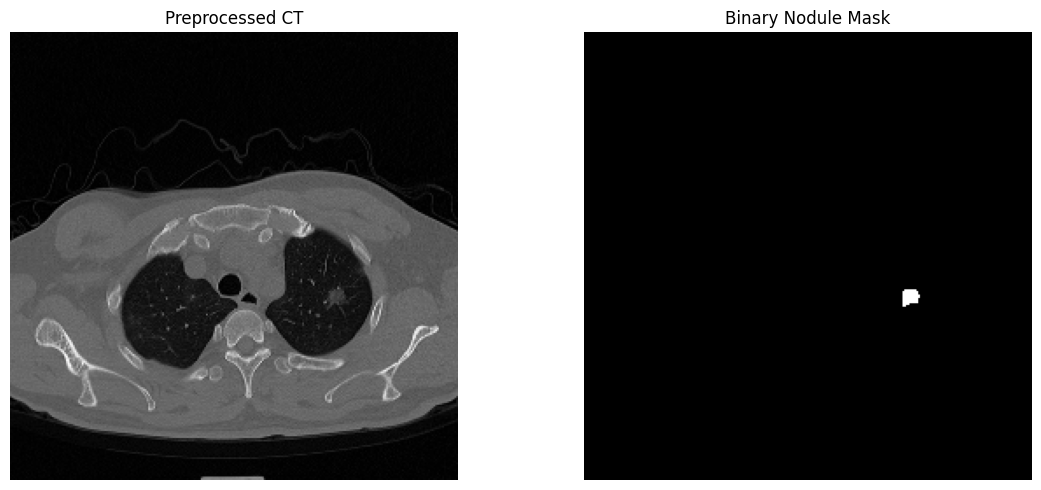

In [28]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.imshow(
    tf.squeeze(sample_image),
    cmap="gray"
)

plt.title("Preprocessed CT")
plt.axis("off")


plt.subplot(1, 2, 2)

plt.imshow(
    tf.squeeze(sample_mask),
    cmap="gray"
)

plt.title("Binary Nodule Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [29]:
def augment(image, mask):

    # --------------------------------------------------
    # Horizontal flip
    # --------------------------------------------------

    flip = tf.random.uniform(()) > 0.5

    image = tf.cond(
        flip,
        lambda: tf.image.flip_left_right(image),
        lambda: image
    )

    mask = tf.cond(
        flip,
        lambda: tf.image.flip_left_right(mask),
        lambda: mask
    )


    # --------------------------------------------------
    # Small brightness adjustment
    # ONLY image - never mask
    # --------------------------------------------------

    image = tf.image.random_brightness(
        image,
        max_delta=0.05
    )


    # --------------------------------------------------
    # Small contrast adjustment
    # ONLY image
    # --------------------------------------------------

    image = tf.image.random_contrast(
        image,
        lower=0.95,
        upper=1.05
    )


    image = tf.clip_by_value(
        image,
        0.0,
        1.0
    )

    return image, mask

In [30]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (
        train_images,
        train_masks
    )
)

train_ds = train_ds.shuffle(
    buffer_size=min(len(train_df), 5000),
    seed=SEED,
    reshuffle_each_iteration=True
)

train_ds = train_ds.map(
    load_image_mask,
    num_parallel_calls=AUTOTUNE
)

train_ds = train_ds.map(
    augment,
    num_parallel_calls=AUTOTUNE
)

train_ds = train_ds.batch(
    BATCH_SIZE,
    drop_remainder=False
)

train_ds = train_ds.prefetch(
    AUTOTUNE
)

In [31]:
valid_ds = tf.data.Dataset.from_tensor_slices(
    (
        valid_images,
        valid_masks
    )
)

valid_ds = valid_ds.map(
    load_image_mask,
    num_parallel_calls=AUTOTUNE
)

valid_ds = valid_ds.batch(
    BATCH_SIZE,
    drop_remainder=False
)

valid_ds = valid_ds.prefetch(
    AUTOTUNE
)

In [32]:
test_ds = tf.data.Dataset.from_tensor_slices(
    (
        test_images,
        test_masks
    )
)

test_ds = test_ds.map(
    load_image_mask,
    num_parallel_calls=AUTOTUNE
)

test_ds = test_ds.batch(
    BATCH_SIZE,
    drop_remainder=False
)

test_ds = test_ds.prefetch(
    AUTOTUNE
)

In [33]:
images, masks = next(iter(train_ds))

print("Image batch:", images.shape)
print("Mask batch :", masks.shape)

Image batch: (16, 256, 256, 1)
Mask batch : (16, 256, 256, 1)


In [34]:
print("IMAGE")
print(
    "Range:",
    float(tf.reduce_min(images)),
    "→",
    float(tf.reduce_max(images))
)

print("\nMASK")
print(
    "Range:",
    float(tf.reduce_min(masks)),
    "→",
    float(tf.reduce_max(masks))
)

print(
    "Unique:",
    np.unique(masks.numpy())
)

IMAGE
Range: 0.0 → 1.0

MASK
Range: 0.0 → 1.0
Unique: [0. 1.]


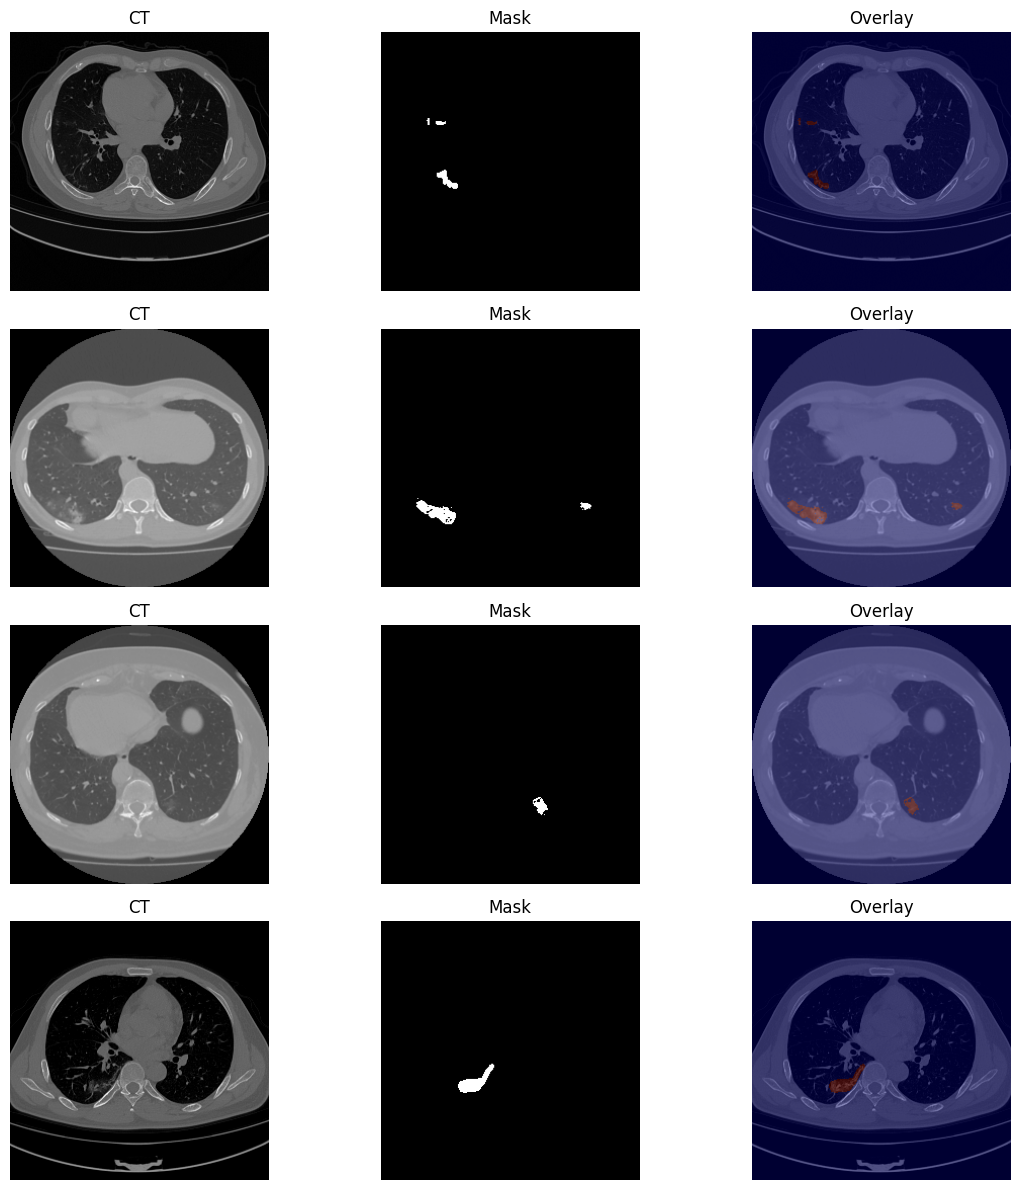

In [35]:
plt.figure(figsize=(12, 12))

NUM_SAMPLES = min(4, images.shape[0])

for i in range(NUM_SAMPLES):

    # CT
    plt.subplot(NUM_SAMPLES, 3, i * 3 + 1)

    plt.imshow(
        tf.squeeze(images[i]),
        cmap="gray"
    )

    plt.title("CT")
    plt.axis("off")


    # Mask
    plt.subplot(NUM_SAMPLES, 3, i * 3 + 2)

    plt.imshow(
        tf.squeeze(masks[i]),
        cmap="gray"
    )

    plt.title("Mask")
    plt.axis("off")


    # Overlay
    plt.subplot(NUM_SAMPLES, 3, i * 3 + 3)

    plt.imshow(
        tf.squeeze(images[i]),
        cmap="gray"
    )

    plt.imshow(
        tf.squeeze(masks[i]),
        cmap="jet",
        alpha=0.4
    )

    plt.title("Overlay")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [36]:
positive_pixels = tf.reduce_sum(masks)

total_pixels = tf.cast(
    tf.size(masks),
    tf.float32
)

positive_percentage = (
    positive_pixels /
    total_pixels
) * 100

background_percentage = (
    100 - positive_percentage
)

print(
    f"Nodule pixels     : "
    f"{positive_percentage.numpy():.4f}%"
)

print(
    f"Background pixels : "
    f"{background_percentage.numpy():.4f}%"
)

Nodule pixels     : 1.5835%
Background pixels : 98.4165%


In [37]:
train_batches = tf.data.experimental.cardinality(
    train_ds
).numpy()

valid_batches = tf.data.experimental.cardinality(
    valid_ds
).numpy()

test_batches = tf.data.experimental.cardinality(
    test_ds
).numpy()

print("Train batches :", train_batches)
print("Valid batches :", valid_batches)
print("Test batches  :", test_batches)

Train batches : 254
Valid batches : 32
Test batches  : 32


In [38]:
import time

start = time.time()

for image_batch, mask_batch in train_ds.take(20):
    pass

elapsed = time.time() - start

print(
    f"20 batches loaded in {elapsed:.2f} seconds"
)

20 batches loaded in 1.50 seconds


In [39]:
print("=" * 60)
print("MODEL 2 — PHASE 2 COMPLETE")
print("=" * 60)

print("\nInput:")
print("CT Scan")

print("\nInput shape:")
print(f"{IMG_HEIGHT} x {IMG_WIDTH} x {IMG_CHANNELS}")

print("\nOutput:")
print("Binary Lung Nodule Segmentation Mask")

print("\nMask encoding:")
print("0 = Background")
print("1 = Nodule")

print("\nBatch size:")
print(BATCH_SIZE)

print("\nPipeline:")
print("tf.data + augmentation + batching + prefetch")

print("\nReady for:")
print("U-Net")

print("=" * 60)

MODEL 2 — PHASE 2 COMPLETE

Input:
CT Scan

Input shape:
256 x 256 x 1

Output:
Binary Lung Nodule Segmentation Mask

Mask encoding:
0 = Background
1 = Nodule

Batch size:
16

Pipeline:
tf.data + augmentation + batching + prefetch

Ready for:
U-Net


In [40]:
import tensorflow as tf
from tensorflow.keras import backend as K

K.clear_session()

print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [41]:
from tensorflow.keras import layers


def conv_block(inputs, filters):

    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        kernel_initializer="he_normal"
    )(inputs)

    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)


    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        kernel_initializer="he_normal"
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    return x

In [42]:
def encoder_block(inputs, filters):

    x = conv_block(
        inputs,
        filters
    )

    p = layers.MaxPooling2D(
        pool_size=(2, 2)
    )(x)

    return x, p

In [43]:
def decoder_block(inputs, skip_features, filters):

    x = layers.Conv2DTranspose(
        filters,
        kernel_size=2,
        strides=2,
        padding="same"
    )(inputs)

    x = layers.Concatenate()([
        x,
        skip_features
    ])

    x = conv_block(
        x,
        filters
    )

    return x

In [44]:
def build_unet(input_shape=(256, 256, 1)):

    inputs = layers.Input(
        shape=input_shape,
        name="ct_image"
    )

    # ==========================================
    # Encoder
    # ==========================================

    s1, p1 = encoder_block(
        inputs,
        32
    )

    s2, p2 = encoder_block(
        p1,
        64
    )

    s3, p3 = encoder_block(
        p2,
        128
    )

    s4, p4 = encoder_block(
        p3,
        256
    )

    # ==========================================
    # Bottleneck
    # ==========================================

    b1 = conv_block(
        p4,
        512
    )

    # ==========================================
    # Decoder
    # ==========================================

    d1 = decoder_block(
        b1,
        s4,
        256
    )

    d2 = decoder_block(
        d1,
        s3,
        128
    )

    d3 = decoder_block(
        d2,
        s2,
        64
    )

    d4 = decoder_block(
        d3,
        s1,
        32
    )

    # ==========================================
    # Segmentation Output
    # ==========================================

    outputs = layers.Conv2D(
        1,
        kernel_size=1,
        activation="sigmoid",
        dtype="float32",
        name="nodule_mask"
    )(d4)

    model = tf.keras.Model(
        inputs,
        outputs,
        name="Lung_Nodule_UNet"
    )

    return model

In [45]:
model = build_unet(
    input_shape=(
        IMG_HEIGHT,
        IMG_WIDTH,
        IMG_CHANNELS
    )
)

print("U-Net created successfully.")

U-Net created successfully.


In [46]:
model.summary()

Model: "Lung_Nodule_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ct_image            │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        320 │ ct_image[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,928 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_4[0][0]  

 Total params: 7,771,297 (29.65 MB)

 Trainable params: 7,765,409 (29.62 MB)

 Non-trainable params: 5,888 (23.00 KB)

In [47]:
print("Model input:")
print(model.input_shape)

print("\nModel output:")
print(model.output_shape)

Model input:
(None, 256, 256, 1)

Model output:
(None, 256, 256, 1)


In [48]:
SMOOTH = 1e-6


def dice_coefficient(y_true, y_pred):

    y_true = tf.cast(
        y_true,
        tf.float32
    )

    y_pred = tf.cast(
        y_pred,
        tf.float32
    )

    y_true = tf.reshape(
        y_true,
        [-1]
    )

    y_pred = tf.reshape(
        y_pred,
        [-1]
    )

    intersection = tf.reduce_sum(
        y_true * y_pred
    )

    dice = (
        2.0 * intersection + SMOOTH
    ) / (
        tf.reduce_sum(y_true)
        + tf.reduce_sum(y_pred)
        + SMOOTH
    )

    return dice

In [49]:
def dice_loss(y_true, y_pred):

    return 1.0 - dice_coefficient(
        y_true,
        y_pred
    )

In [50]:
bce = tf.keras.losses.BinaryCrossentropy()


def bce_dice_loss(y_true, y_pred):

    y_true = tf.cast(
        y_true,
        tf.float32
    )

    y_pred = tf.cast(
        y_pred,
        tf.float32
    )

    bce_value = bce(
        y_true,
        y_pred
    )

    dice_value = dice_loss(
        y_true,
        y_pred
    )

    return bce_value + dice_value

In [51]:
def iou_metric(y_true, y_pred):

    y_true = tf.cast(
        y_true > 0.5,
        tf.float32
    )

    y_pred = tf.cast(
        y_pred > 0.5,
        tf.float32
    )

    y_true = tf.reshape(
        y_true,
        [-1]
    )

    y_pred = tf.reshape(
        y_pred,
        [-1]
    )

    intersection = tf.reduce_sum(
        y_true * y_pred
    )

    union = (
        tf.reduce_sum(y_true)
        + tf.reduce_sum(y_pred)
        - intersection
    )

    return (
        intersection + SMOOTH
    ) / (
        union + SMOOTH
    )

In [52]:
LEARNING_RATE = 1e-4

optimizer = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)

model.compile(

    optimizer=optimizer,

    loss=bce_dice_loss,

    metrics=[
        dice_coefficient,
        iou_metric,

        tf.keras.metrics.Precision(
            name="precision",
            thresholds=0.5
        ),

        tf.keras.metrics.Recall(
            name="recall",
            thresholds=0.5
        )
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [53]:
sample_images, sample_masks = next(
    iter(train_ds)
)

print("Input batch:")
print(sample_images.shape)

predictions = model(
    sample_images[:1],
    training=False
)

print("\nPrediction:")
print(predictions.shape)

print(
    "Prediction range:",
    float(tf.reduce_min(predictions)),
    "→",
    float(tf.reduce_max(predictions))
)

Input batch:
(16, 256, 256, 1)

Prediction:
(1, 256, 256, 1)
Prediction range: 0.410481721162796 → 0.6667659878730774


In [54]:
test_loss = bce_dice_loss(
    sample_masks[:1],
    predictions
)

print(
    "Initial BCE + Dice Loss:",
    float(test_loss)
)

Initial BCE + Dice Loss: 1.6757826805114746


In [55]:
initial_dice = dice_coefficient(
    sample_masks[:1],
    predictions
)

initial_iou = iou_metric(
    sample_masks[:1],
    predictions
)

print(
    "Initial Dice:",
    float(initial_dice)
)

print(
    "Initial IoU:",
    float(initial_iou)
)

Initial Dice: 0.04299173131585121
Initial IoU: 0.021446537226438522


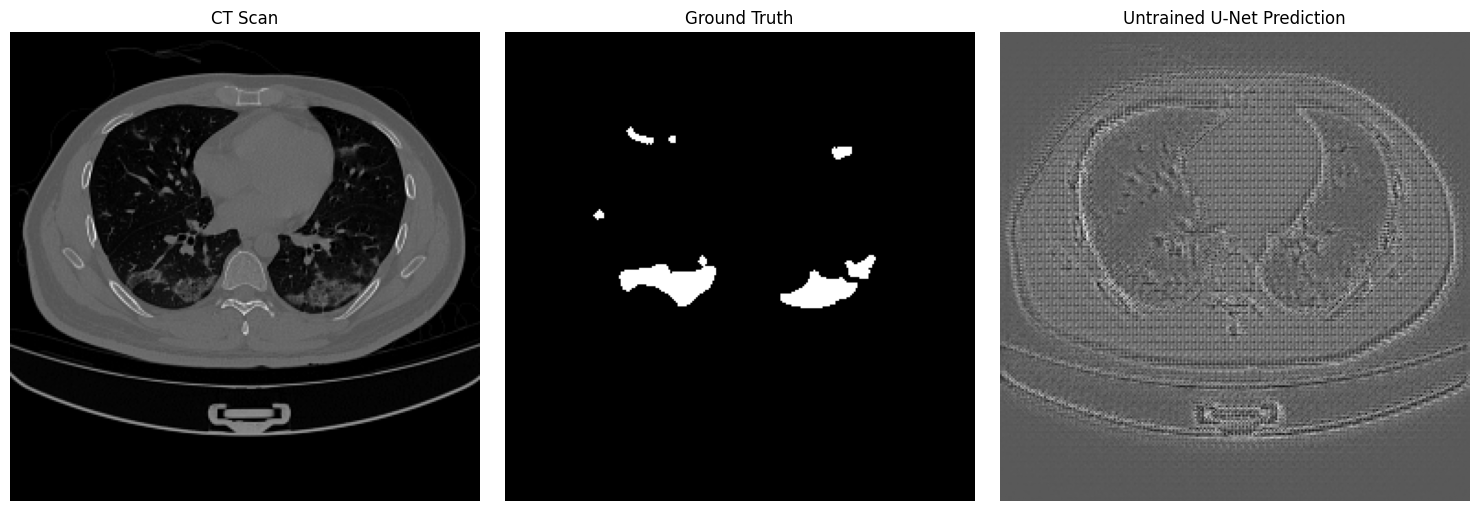

In [56]:
pred_mask = predictions[0].numpy()

plt.figure(figsize=(15, 5))


# Original CT

plt.subplot(1, 3, 1)

plt.imshow(
    tf.squeeze(sample_images[0]),
    cmap="gray"
)

plt.title("CT Scan")
plt.axis("off")


# Ground Truth

plt.subplot(1, 3, 2)

plt.imshow(
    tf.squeeze(sample_masks[0]),
    cmap="gray"
)

plt.title("Ground Truth")
plt.axis("off")


# Untrained prediction

plt.subplot(1, 3, 3)

plt.imshow(
    pred_mask.squeeze(),
    cmap="gray"
)

plt.title("Untrained U-Net Prediction")
plt.axis("off")


plt.tight_layout()
plt.show()

In [57]:
print("=" * 60)
print("MODEL 2 — PHASE 3 COMPLETE")
print("=" * 60)

print("\nModel:")
print(model.name)

print("\nInput:")
print(model.input_shape)

print("\nOutput:")
print(model.output_shape)

print("\nLoss:")
print("Binary Cross-Entropy + Dice Loss")

print("\nMetrics:")
print("Dice Coefficient")
print("IoU")
print("Precision")
print("Recall")

print("\nOptimizer:")
print("Adam")

print("\nLearning Rate:")
print(LEARNING_RATE)

print("\nMixed Precision:")
print(tf.keras.mixed_precision.global_policy())

print("\nStatus:")
print("READY FOR TRAINING")

print("=" * 60)

MODEL 2 — PHASE 3 COMPLETE

Model:
Lung_Nodule_UNet

Input:
(None, 256, 256, 1)

Output:
(None, 256, 256, 1)

Loss:
Binary Cross-Entropy + Dice Loss

Metrics:
Dice Coefficient
IoU
Precision
Recall

Optimizer:
Adam

Learning Rate:
0.0001

Mixed Precision:
<DTypePolicy "float32">

Status:
READY FOR TRAINING


In [58]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

!nvidia-smi

TensorFlow: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Sat Aug  1 07:19:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P0             27W /   70W |   13881MiB /  15360MiB |      0%      Default |
|                                        

In [59]:
# ============================================================
# TRAINING CONFIGURATION
# ============================================================

EPOCHS = 30

MODEL_PATH = "/content/best_lung_nodule_unet.keras"
FINAL_MODEL_PATH = "/content/final_lung_nodule_unet.keras"
CSV_LOG_PATH = "/content/unet_training_log.csv"

print("Epochs:", EPOCHS)
print("Best model:", MODEL_PATH)

Epochs: 30
Best model: /content/best_lung_nodule_unet.keras


In [60]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=MODEL_PATH,
    monitor="val_dice_coefficient",
    mode="max",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

In [61]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_dice_coefficient",
    mode="max",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

In [62]:
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_dice_coefficient",
    mode="max",
    factor=0.5,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

In [63]:
csv_logger = tf.keras.callbacks.CSVLogger(
    CSV_LOG_PATH,
    append=False
)

In [64]:
callbacks = [
    checkpoint,
    early_stopping,
    reduce_lr,
    csv_logger
]

print("Callbacks ready:", len(callbacks))

Callbacks ready: 4


In [65]:
train_images_batch, train_masks_batch = next(iter(train_ds))
valid_images_batch, valid_masks_batch = next(iter(valid_ds))

print("TRAIN")
print("Images:", train_images_batch.shape)
print("Masks :", train_masks_batch.shape)

print("\nVALIDATION")
print("Images:", valid_images_batch.shape)
print("Masks :", valid_masks_batch.shape)

print("\nMask values:")
print(
    tf.unique(
        tf.reshape(train_masks_batch, [-1])
    ).y.numpy()
)

TRAIN
Images: (16, 256, 256, 1)
Masks : (16, 256, 256, 1)

VALIDATION
Images: (16, 256, 256, 1)
Masks : (16, 256, 256, 1)

Mask values:
[0. 1.]


In [66]:
print("Model:", model.name)
print("Input :", model.input_shape)
print("Output:", model.output_shape)

print("\nParameters:")
print(f"{model.count_params():,}")

Model: Lung_Nodule_UNet
Input : (None, 256, 256, 1)
Output: (None, 256, 256, 1)

Parameters:
7,771,297


In [67]:
history = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
254/254 ━━━━━━━━━━━━━━━━━━━━ 0s 428ms/step - dice_coefficient: 0.0439 - iou_metric: 0.0809 - loss: 1.4292 - precision: 0.0516 - recall: 0.4010
Epoch 1: val_dice_coefficient improved from None to 0.04150, saving model to /content/best_lung_nodule_unet.keras

Epoch 1: finished saving model to /content/best_lung_nodule_unet.keras
254/254 ━━━━━━━━━━━━━━━━━━━━ 175s 486ms/step - dice_coefficient: 0.0556 - iou_metric: 0.1362 - loss: 1.2789 - precision: 0.0831 - recall: 0.3092 - val_dice_coefficient: 0.0415 - val_iou_metric: 0.0547 - val_loss: 1.1949 - val_precision: 0.1357 - val_recall: 0.0957 - learning_rate: 1.0000e-04
Epoch 2/30
254/254 ━━━━━━━━━━━━━━━━━━━━ 0s 316ms/step - dice_coefficient: 0.0864 - iou_metric: 0.2525 - loss: 1.1099 - precision: 0.4852 - recall: 0.3710
Epoch 2: val_dice_coefficient improved from 0.04150 to 0.09596, saving model to /content/best_lung_nodule_unet.keras

Epoch 2: finished saving model to /content/best_lung_nodule_unet.keras
254/254 ━━━━━━━━━━━━━━━━

In [68]:
model.save(
    FINAL_MODEL_PATH
)

print("Final model saved:")
print(FINAL_MODEL_PATH)

print("\nBest model saved:")
print(MODEL_PATH)

Final model saved:
/content/final_lung_nodule_unet.keras

Best model saved:
/content/best_lung_nodule_unet.keras


In [69]:
import numpy as np

best_epoch = (
    np.argmax(history.history["val_dice_coefficient"]) + 1
)

best_dice = np.max(
    history.history["val_dice_coefficient"]
)

print("Best Epoch:", best_epoch)
print(f"Best Validation Dice: {best_dice:.4f}")

Best Epoch: 30
Best Validation Dice: 0.8879


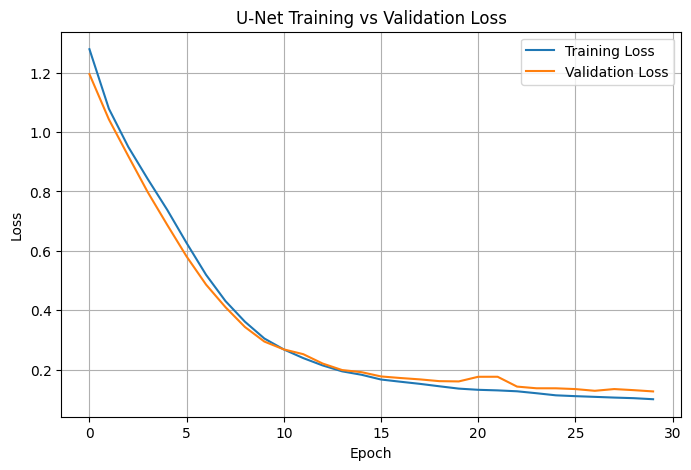

In [70]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("U-Net Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

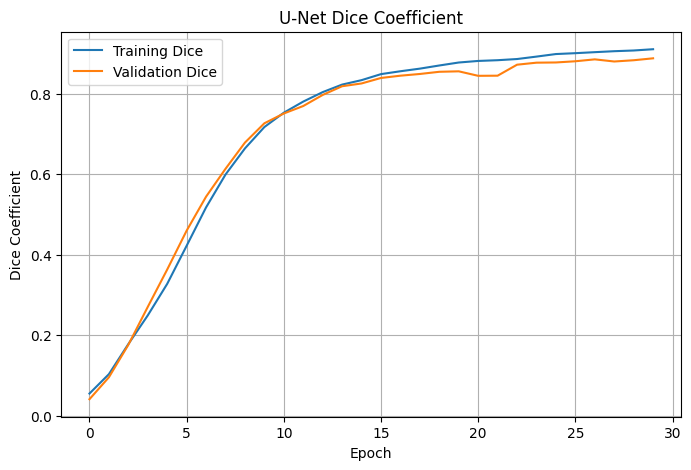

In [71]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["dice_coefficient"],
    label="Training Dice"
)

plt.plot(
    history.history["val_dice_coefficient"],
    label="Validation Dice"
)

plt.xlabel("Epoch")
plt.ylabel("Dice Coefficient")
plt.title("U-Net Dice Coefficient")
plt.legend()
plt.grid(True)

plt.show()

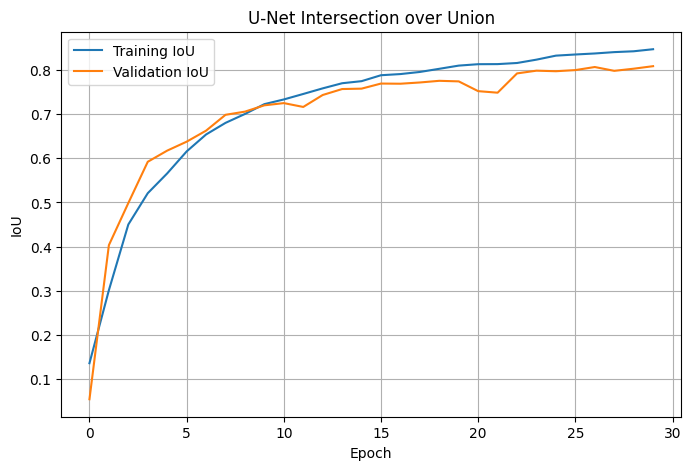

In [72]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["iou_metric"],
    label="Training IoU"
)

plt.plot(
    history.history["val_iou_metric"],
    label="Validation IoU"
)

plt.xlabel("Epoch")
plt.ylabel("IoU")
plt.title("U-Net Intersection over Union")
plt.legend()
plt.grid(True)

plt.show()

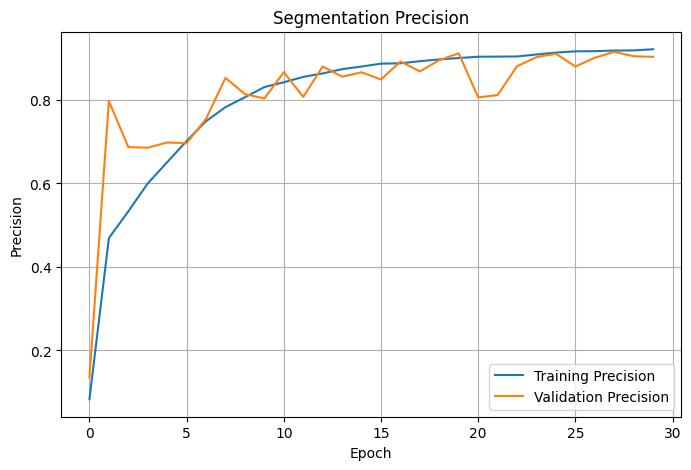

In [73]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["precision"],
    label="Training Precision"
)

plt.plot(
    history.history["val_precision"],
    label="Validation Precision"
)

plt.xlabel("Epoch")
plt.ylabel("Precision")
plt.title("Segmentation Precision")
plt.legend()
plt.grid(True)

plt.show()

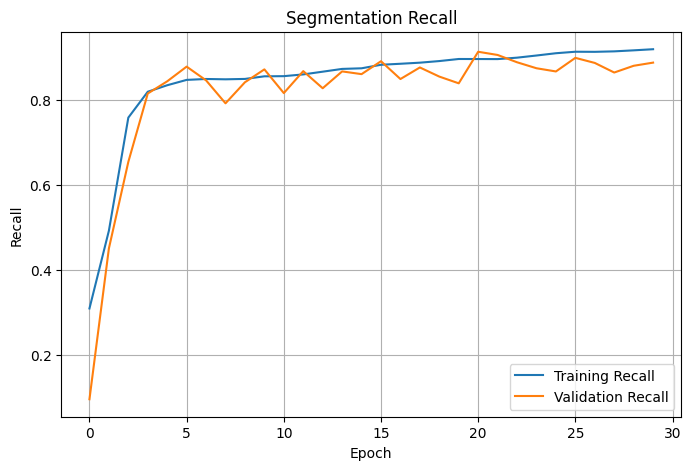

In [74]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["recall"],
    label="Training Recall"
)

plt.plot(
    history.history["val_recall"],
    label="Validation Recall"
)

plt.xlabel("Epoch")
plt.ylabel("Recall")
plt.title("Segmentation Recall")
plt.legend()
plt.grid(True)

plt.show()

In [75]:
best_model = tf.keras.models.load_model(
    MODEL_PATH,
    custom_objects={
        "bce_dice_loss": bce_dice_loss,
        "dice_coefficient": dice_coefficient,
        "iou_metric": iou_metric
    }
)

print("Best model loaded successfully.")

Best model loaded successfully.


In [76]:
val_results = best_model.evaluate(
    valid_ds,
    verbose=1,
    return_dict=True
)

print("\nValidation Results")

for metric, value in val_results.items():
    print(f"{metric:25s}: {value:.4f}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 134ms/step - dice_coefficient: 0.8879 - iou_metric: 0.8082 - loss: 0.1269 - precision: 0.9032 - recall: 0.8875

Validation Results
dice_coefficient         : 0.8879
iou_metric               : 0.8082
loss                     : 0.1269
precision                : 0.9032
recall                   : 0.8875


In [77]:
images, masks = next(iter(valid_ds))

predictions = best_model.predict(
    images[:4],
    verbose=0
)

predicted_masks = (
    predictions > 0.5
).astype("float32")

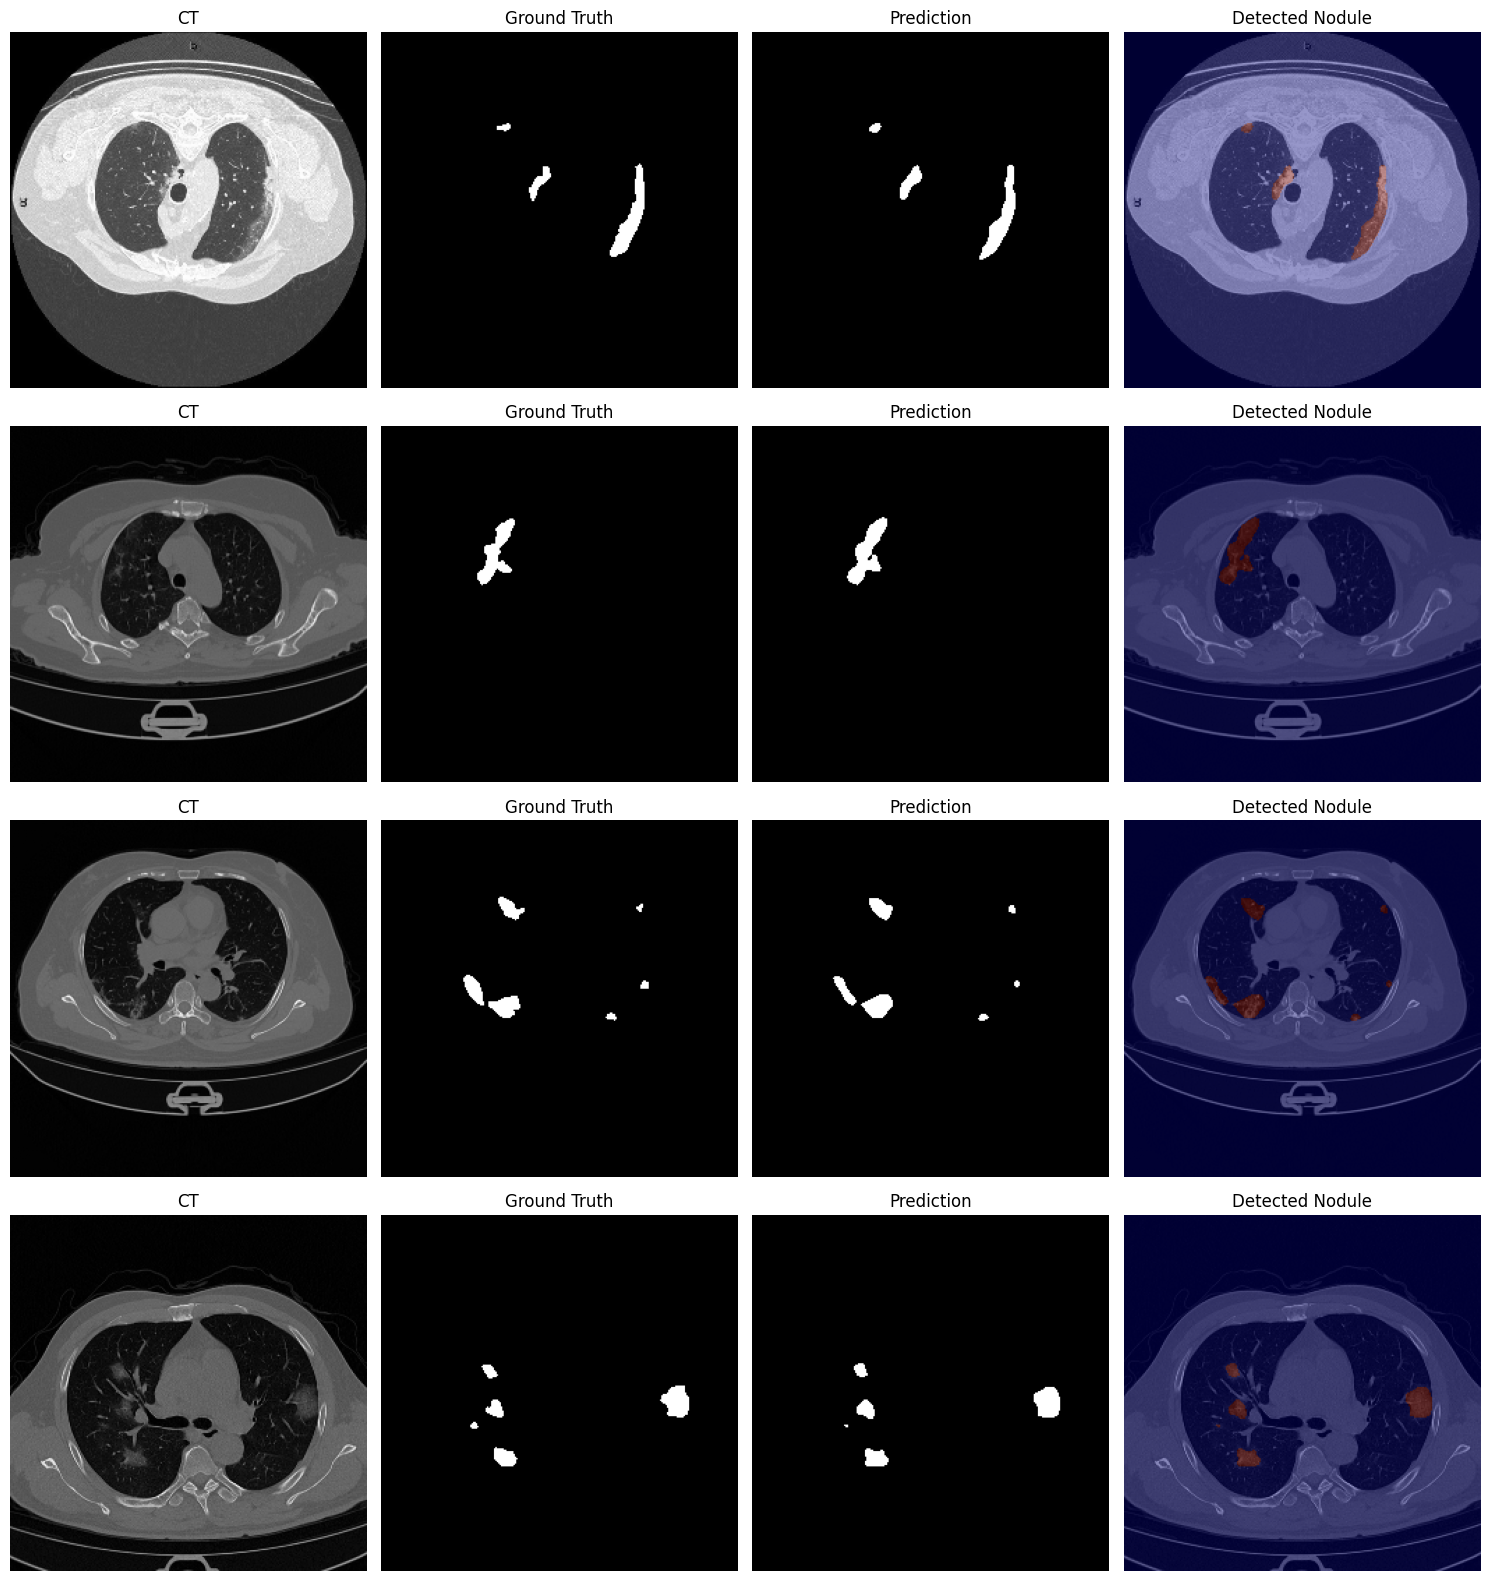

In [78]:
plt.figure(figsize=(15, 16))

for i in range(4):

    # CT
    plt.subplot(4, 4, i * 4 + 1)

    plt.imshow(
        tf.squeeze(images[i]),
        cmap="gray"
    )

    plt.title("CT")
    plt.axis("off")


    # Ground Truth
    plt.subplot(4, 4, i * 4 + 2)

    plt.imshow(
        tf.squeeze(masks[i]),
        cmap="gray"
    )

    plt.title("Ground Truth")
    plt.axis("off")


    # Prediction
    plt.subplot(4, 4, i * 4 + 3)

    plt.imshow(
        predicted_masks[i].squeeze(),
        cmap="gray"
    )

    plt.title("Prediction")
    plt.axis("off")


    # Overlay
    plt.subplot(4, 4, i * 4 + 4)

    plt.imshow(
        tf.squeeze(images[i]),
        cmap="gray"
    )

    plt.imshow(
        predicted_masks[i].squeeze(),
        cmap="jet",
        alpha=0.4
    )

    plt.title("Detected Nodule")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [79]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

MODEL_PATH = "/content/best_lung_nodule_unet.keras"

best_model = tf.keras.models.load_model(
    MODEL_PATH,
    custom_objects={
        "bce_dice_loss": bce_dice_loss,
        "dice_coefficient": dice_coefficient,
        "iou_metric": iou_metric
    }
)

print("Best model loaded successfully.")

Best model loaded successfully.


In [80]:
test_results = best_model.evaluate(
    test_ds,
    verbose=1,
    return_dict=True
)

print("\n" + "=" * 60)
print("FINAL TEST RESULTS")
print("=" * 60)

for metric, value in test_results.items():
    print(f"{metric:25s}: {value:.4f}")

print("=" * 60)


32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 122ms/step - dice_coefficient: 0.8981 - iou_metric: 0.8243 - loss: 0.1157 - precision: 0.9139 - recall: 0.8975

FINAL TEST RESULTS
dice_coefficient         : 0.8981
iou_metric               : 0.8243
loss                     : 0.1157
precision                : 0.9139
recall                   : 0.8975


In [81]:
all_images = []
all_masks = []
all_predictions = []

for images, masks in test_ds:

    predictions = best_model.predict(
        images,
        verbose=0
    )

    all_images.append(images.numpy())
    all_masks.append(masks.numpy())
    all_predictions.append(predictions)


all_images = np.concatenate(
    all_images,
    axis=0
)

all_masks = np.concatenate(
    all_masks,
    axis=0
)

all_predictions = np.concatenate(
    all_predictions,
    axis=0
)

print("Images      :", all_images.shape)
print("Masks       :", all_masks.shape)
print("Predictions :", all_predictions.shape)

Images      : (507, 256, 256, 1)
Masks       : (507, 256, 256, 1)
Predictions : (507, 256, 256, 1)


In [82]:
def calculate_dice_np(y_true, y_pred, smooth=1e-6):

    y_true = y_true.astype(np.float32)
    y_pred = y_pred.astype(np.float32)

    intersection = np.sum(
        y_true * y_pred
    )

    return (
        (2.0 * intersection + smooth) /
        (
            np.sum(y_true) +
            np.sum(y_pred) +
            smooth
        )
    )


thresholds = np.arange(
    0.20,
    0.85,
    0.05
)

threshold_results = []

for threshold in thresholds:

    binary_predictions = (
        all_predictions >= threshold
    ).astype(np.float32)

    dice = calculate_dice_np(
        all_masks,
        binary_predictions
    )

    threshold_results.append({
        "Threshold": threshold,
        "Dice": dice
    })


threshold_df = pd.DataFrame(
    threshold_results
)

threshold_df

,Threshold,Dice
0,0.20,0.905651
1,0.25,0.905793
2,0.30,0.905984
3,0.35,0.906009
4,0.40,0.905879
5,0.45,0.905728
6,0.50,0.905622
7,0.55,0.905480
8,0.60,0.905292
9,0.65,0.905050


In [83]:
best_row = threshold_df.loc[
    threshold_df["Dice"].idxmax()
]

BEST_THRESHOLD = float(
    best_row["Threshold"]
)

BEST_THRESHOLD_DICE = float(
    best_row["Dice"]
)

print(
    f"Best threshold: {BEST_THRESHOLD:.2f}"
)

print(
    f"Dice at best threshold: "
    f"{BEST_THRESHOLD_DICE:.4f}"
)

Best threshold: 0.35
Dice at best threshold: 0.9060


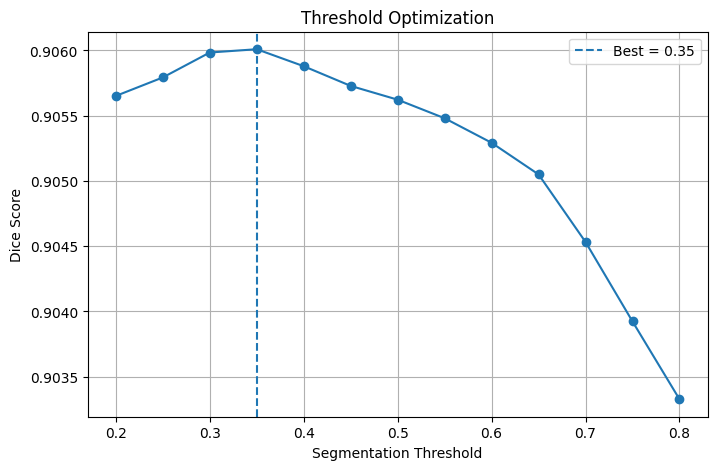

In [84]:
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Dice"],
    marker="o"
)

plt.axvline(
    BEST_THRESHOLD,
    linestyle="--",
    label=f"Best = {BEST_THRESHOLD:.2f}"
)

plt.xlabel("Segmentation Threshold")
plt.ylabel("Dice Score")
plt.title("Threshold Optimization")
plt.legend()
plt.grid(True)

plt.show()

In [85]:
binary_predictions = (
    all_predictions >= BEST_THRESHOLD
).astype(np.float32)

print(
    "Using threshold:",
    BEST_THRESHOLD
)

print(
    "Unique prediction values:",
    np.unique(binary_predictions)
)

Using threshold: 0.35
Unique prediction values: [0. 1.]


In [86]:
def image_dice(y_true, y_pred, smooth=1e-6):

    y_true = y_true.astype(np.float32)
    y_pred = y_pred.astype(np.float32)

    intersection = np.sum(
        y_true * y_pred
    )

    return (
        2.0 * intersection + smooth
    ) / (
        np.sum(y_true) +
        np.sum(y_pred) +
        smooth
    )

In [87]:
def image_iou(y_true, y_pred, smooth=1e-6):

    y_true = y_true.astype(np.float32)
    y_pred = y_pred.astype(np.float32)

    intersection = np.sum(
        y_true * y_pred
    )

    union = (
        np.sum(y_true)
        + np.sum(y_pred)
        - intersection
    )

    return (
        intersection + smooth
    ) / (
        union + smooth
    )

In [88]:
dice_scores = []
iou_scores = []

for i in range(len(all_masks)):

    dice = image_dice(
        all_masks[i],
        binary_predictions[i]
    )

    iou = image_iou(
        all_masks[i],
        binary_predictions[i]
    )

    dice_scores.append(dice)
    iou_scores.append(iou)


dice_scores = np.array(dice_scores)
iou_scores = np.array(iou_scores)

print(
    f"Mean Dice   : {dice_scores.mean():.4f}"
)

print(
    f"Median Dice : {np.median(dice_scores):.4f}"
)

print(
    f"Mean IoU    : {iou_scores.mean():.4f}"
)

print(
    f"Median IoU  : {np.median(iou_scores):.4f}"
)

Mean Dice   : 0.8185
Median Dice : 0.8921
Mean IoU    : 0.7280
Median IoU  : 0.8053


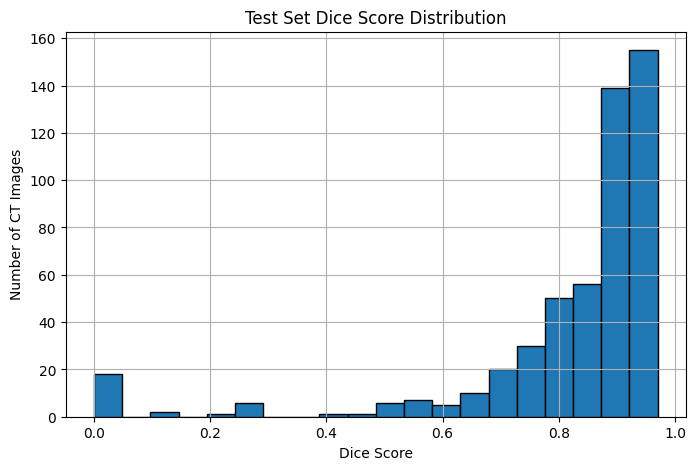

In [89]:
plt.figure(figsize=(8, 5))

plt.hist(
    dice_scores,
    bins=20,
    edgecolor="black"
)

plt.xlabel("Dice Score")
plt.ylabel("Number of CT Images")

plt.title(
    "Test Set Dice Score Distribution"
)

plt.grid(True)

plt.show()

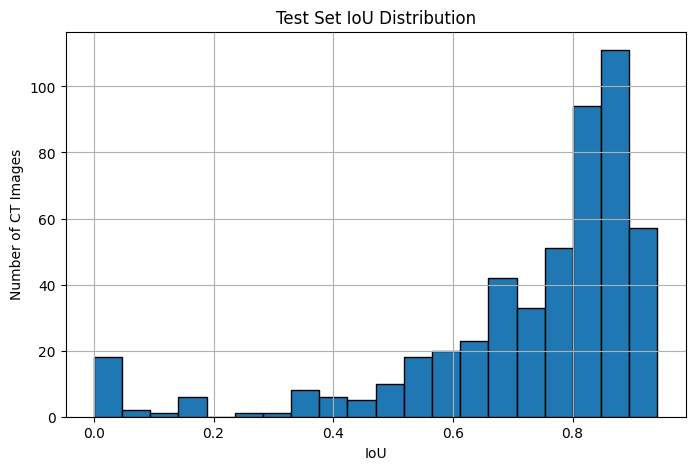

In [90]:
plt.figure(figsize=(8, 5))

plt.hist(
    iou_scores,
    bins=20,
    edgecolor="black"
)

plt.xlabel("IoU")
plt.ylabel("Number of CT Images")

plt.title(
    "Test Set IoU Distribution"
)

plt.grid(True)

plt.show()

In [91]:
best_index = np.argmax(
    dice_scores
)

print(
    "Best prediction index:",
    best_index
)

print(
    f"Dice: {dice_scores[best_index]:.4f}"
)

print(
    f"IoU : {iou_scores[best_index]:.4f}"
)

Best prediction index: 125
Dice: 0.9701
IoU : 0.9419


In [92]:
worst_index = np.argmin(
    dice_scores
)

print(
    "Worst prediction index:",
    worst_index
)

print(
    f"Dice: {dice_scores[worst_index]:.4f}"
)

print(
    f"IoU : {iou_scores[worst_index]:.4f}"
)

Worst prediction index: 206
Dice: 0.0000
IoU : 0.0000


In [94]:
def visualize_prediction(index):

    image = all_images[index].squeeze()

    true_mask = (
        all_masks[index]
        .squeeze()
    )

    probability = (
        all_predictions[index]
        .squeeze()
    )

    predicted_mask = (
        binary_predictions[index]
        .squeeze()
    )


    plt.figure(
        figsize=(18, 4)
    )


    # CT
    plt.subplot(1, 5, 1)

    plt.imshow(
        image,
        cmap="gray"
    )

    plt.title("CT Scan")
    plt.axis("off")


    # Ground truth
    plt.subplot(1, 5, 2)

    plt.imshow(
        true_mask,
        cmap="gray"
    )

    plt.title("Ground Truth")
    plt.axis("off")


    # Probability map
    plt.subplot(1, 5, 3)

    plt.imshow(
        probability,
        cmap="jet"
    )

    plt.title("Probability Map")
    plt.axis("off")


    # Binary prediction
    plt.subplot(1, 5, 4)

    plt.imshow(
        predicted_mask,
        cmap="gray"
    )

    plt.title("Predicted Mask")
    plt.axis("off")


    # Overlay
    plt.subplot(1, 5, 5)

    plt.imshow(
        image,
        cmap="gray"
    )

    plt.imshow(
        predicted_mask,
        cmap="jet",
        alpha=0.4
    )

    plt.title(
        f"Overlay\nDice: "
        f"{dice_scores[index]:.3f}"
    )

    plt.axis("off")


    plt.tight_layout()
    plt.show()

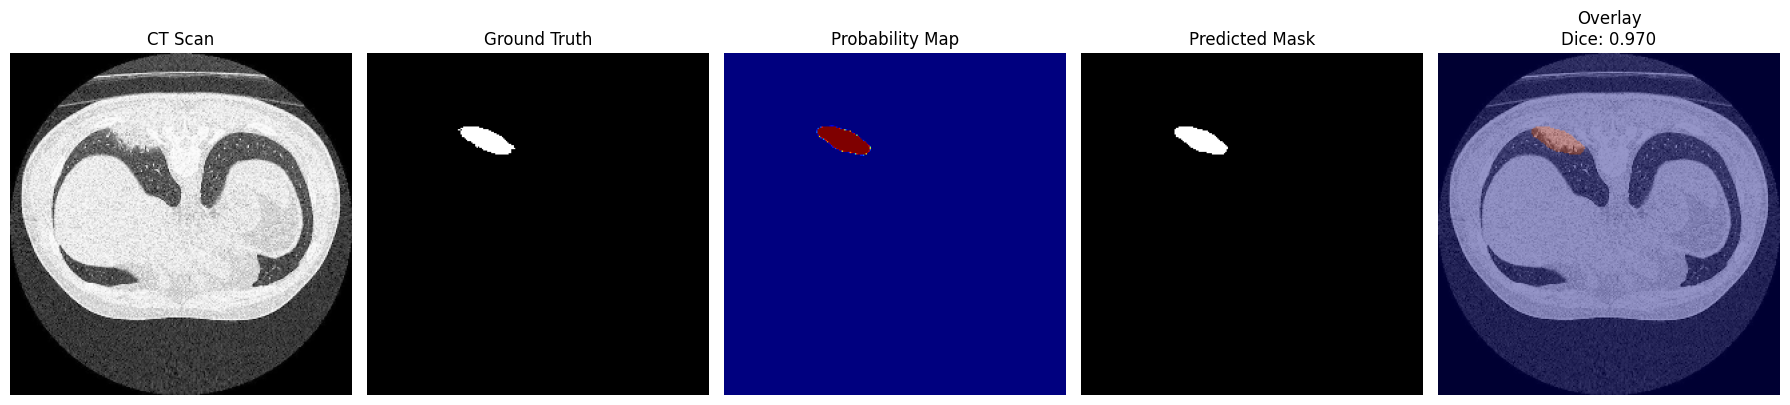

In [95]:
visualize_prediction(
    best_index
)

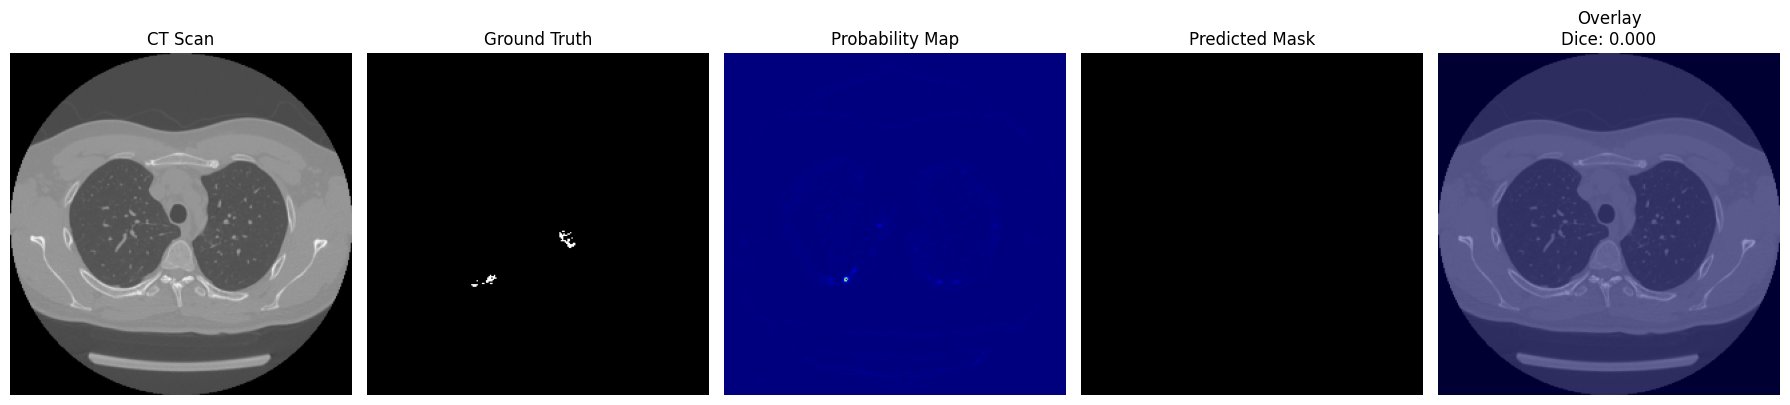

In [96]:
visualize_prediction(
    worst_index
)


Sample 55 | Dice: 0.7500 | IoU: 0.6000


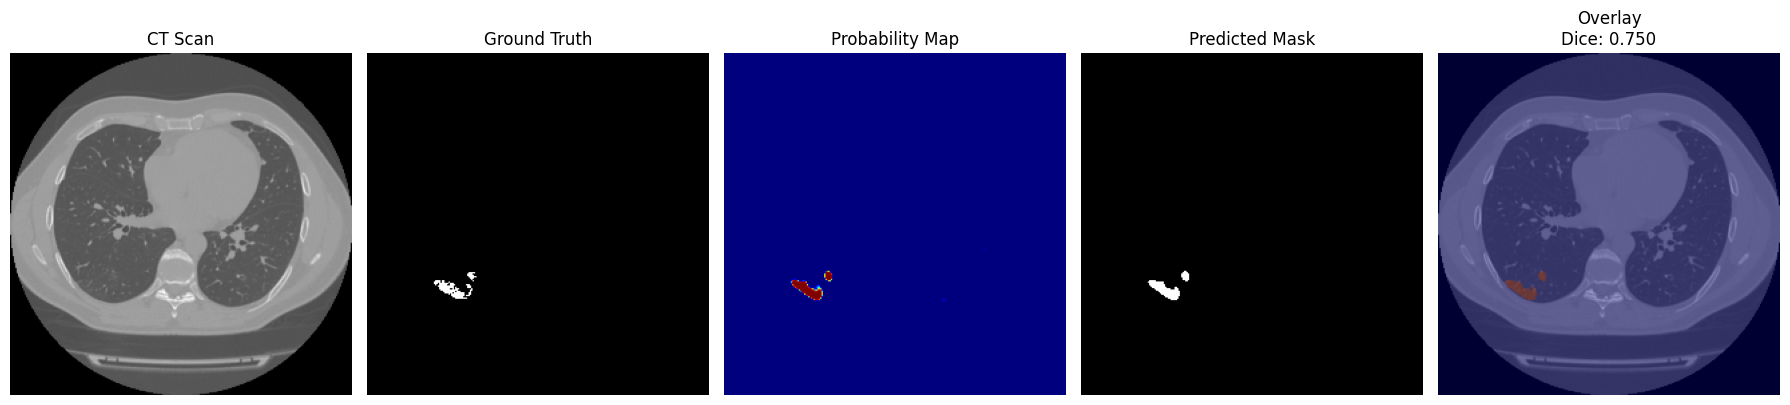


Sample 464 | Dice: 0.9264 | IoU: 0.8628


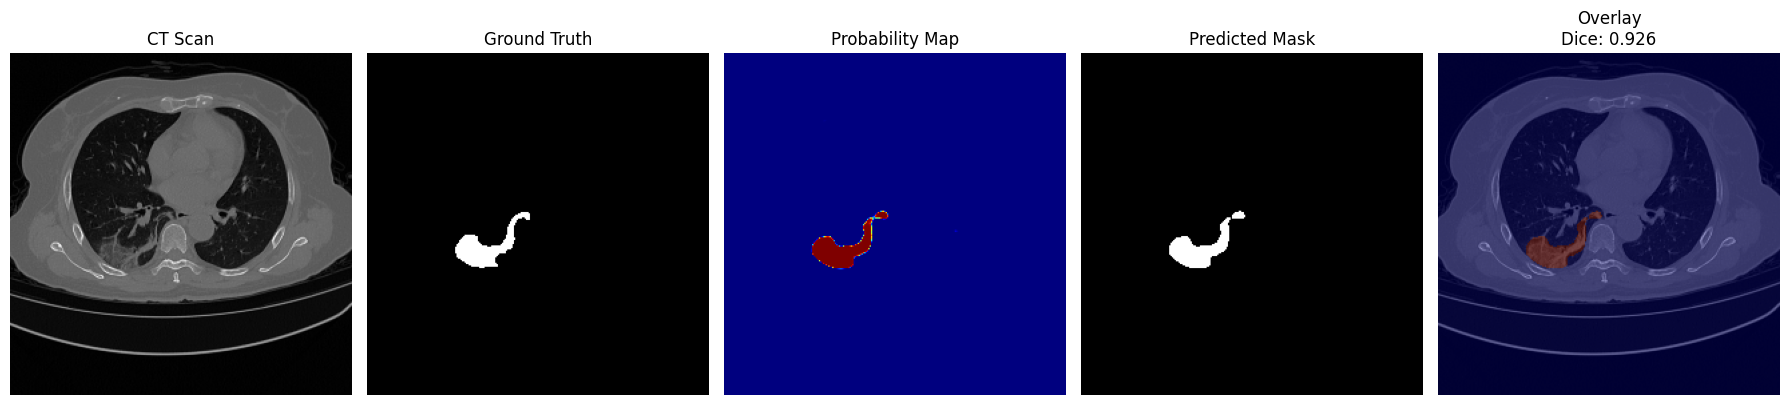


Sample 139 | Dice: 0.0000 | IoU: 0.0000


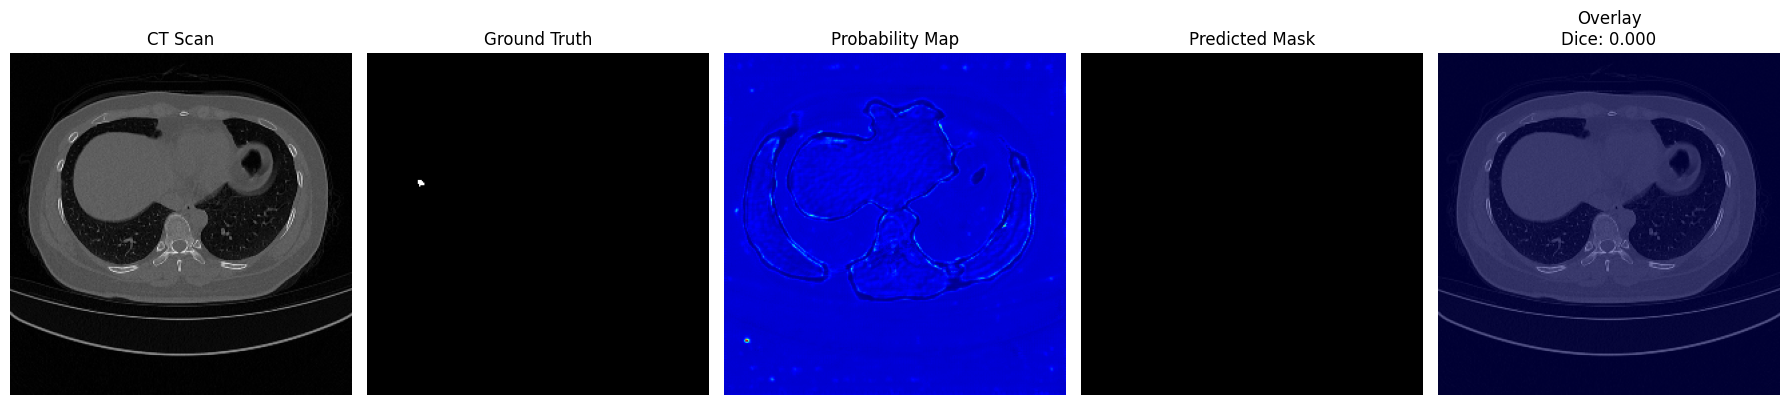


Sample 290 | Dice: 0.9344 | IoU: 0.8769


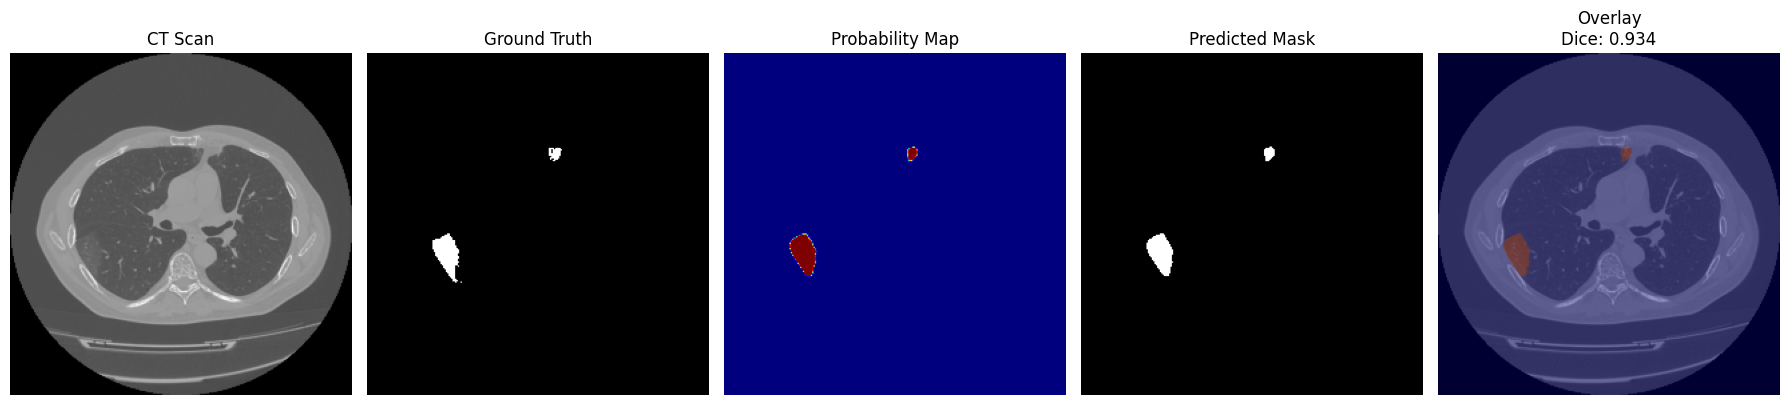


Sample 138 | Dice: 0.9097 | IoU: 0.8344


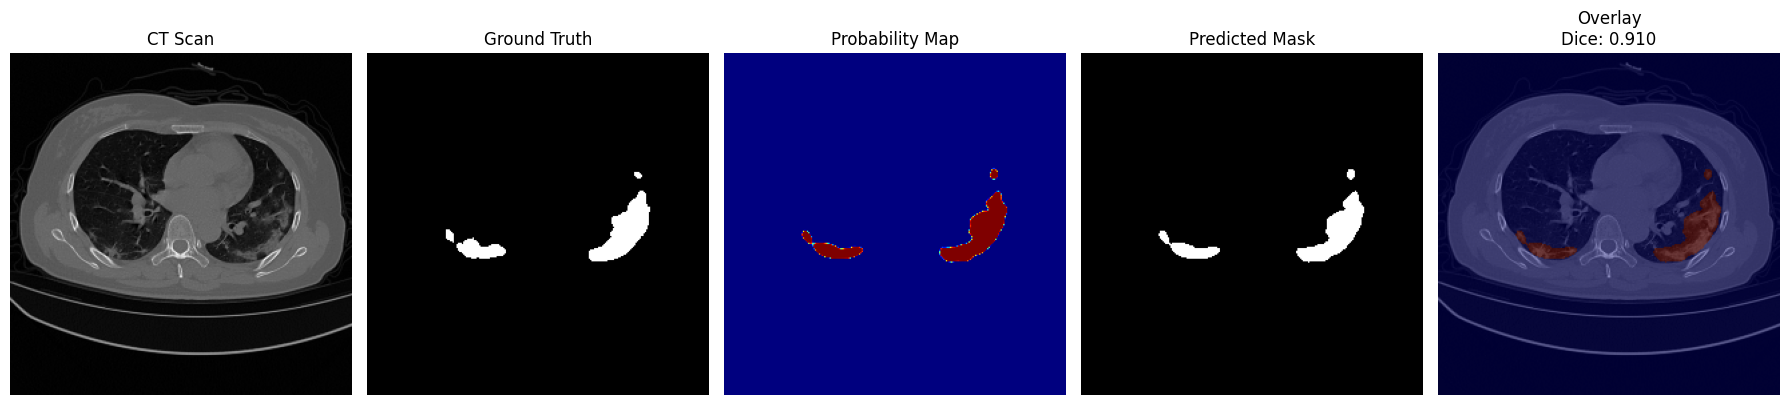

In [97]:
import random

random_indices = random.sample(
    range(len(all_images)),
    min(5, len(all_images))
)

for index in random_indices:

    print(
        f"\nSample {index}"
        f" | Dice: {dice_scores[index]:.4f}"
        f" | IoU: {iou_scores[index]:.4f}"
    )

    visualize_prediction(index)

In [98]:
true_flat = all_masks.reshape(-1)

pred_flat = binary_predictions.reshape(-1)

TP = np.sum(
    (true_flat == 1) &
    (pred_flat == 1)
)

FP = np.sum(
    (true_flat == 0) &
    (pred_flat == 1)
)

FN = np.sum(
    (true_flat == 1) &
    (pred_flat == 0)
)

precision = TP / (
    TP + FP + 1e-6
)

recall = TP / (
    TP + FN + 1e-6
)

print(
    f"Precision: {precision:.4f}"
)

print(
    f"Recall   : {recall:.4f}"
)

Precision: 0.9077
Recall   : 0.9043


In [99]:
final_dice = calculate_dice_np(
    all_masks,
    binary_predictions
)

intersection = np.sum(
    all_masks *
    binary_predictions
)

union = (
    np.sum(all_masks)
    + np.sum(binary_predictions)
    - intersection
)

final_iou = (
    intersection + 1e-6
) / (
    union + 1e-6
)

print(
    f"Final Dice: {final_dice:.4f}"
)

print(
    f"Final IoU : {final_iou:.4f}"
)

Final Dice: 0.9060
Final IoU : 0.8282


In [100]:
final_results = pd.DataFrame({
    "Metric": [
        "Dice",
        "IoU",
        "Precision",
        "Recall",
        "Threshold"
    ],

    "Value": [
        final_dice,
        final_iou,
        precision,
        recall,
        BEST_THRESHOLD
    ]
})

final_results

,Metric,Value
0,Dice,0.906009
1,IoU,0.828169
2,Precision,0.907679
3,Recall,0.904345
4,Threshold,0.350000


In [101]:
final_results.to_csv(
    "/content/lung_nodule_test_results.csv",
    index=False
)

threshold_df.to_csv(
    "/content/threshold_analysis.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.


In [102]:
print("=" * 60)
print("MODEL 2 — FINAL TEST EVALUATION")
print("=" * 60)

print(
    f"Best Threshold : {BEST_THRESHOLD:.2f}"
)

print(
    f"Final Dice     : {final_dice:.4f}"
)

print(
    f"Final IoU      : {final_iou:.4f}"
)

print(
    f"Precision      : {precision:.4f}"
)

print(
    f"Recall         : {recall:.4f}"
)

print(
    f"Mean Img Dice  : {dice_scores.mean():.4f}"
)

print(
    f"Mean Img IoU   : {iou_scores.mean():.4f}"
)

print("=" * 60)

MODEL 2 — FINAL TEST EVALUATION
Best Threshold : 0.35
Final Dice     : 0.9060
Final IoU      : 0.8282
Precision      : 0.9077
Recall         : 0.9043
Mean Img Dice  : 0.8185
Mean Img IoU   : 0.7280


In [103]:
from google.colab import files

files.download("/content/best_lung_nodule_unet.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [104]:
from google.colab import files

files.download("/content/unet_training_log.csv")
files.download("/content/lung_nodule_test_results.csv")
files.download("/content/threshold_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>